# Lab01 - sprint 1

## Random Variable 03 (r_def)

### Description

#### 1. О величине

На карте пластины берём все дефектные чипы (значение 2) и усредняем их координаты. Получается центроид дефектов — «центр масс» брака на пластине. $r_{def}$ — расстояние от центра карты до этого центроида, нормированное на то же $\max d$, что и для n_edge (расстояние до самого дальнего чипа):

$$\bar i=\frac1k\sum_{m=1}^{k} i_m,\quad \bar j=\frac1k\sum_{m=1}^{k} j_m,\qquad r_{def}=\frac{\sqrt{(\bar i-i_c)^2+(\bar j-j_c)^2}}{\max d},$$

где $k$ = n_defect — число дефектных чипов на пластине. Значит, $r_{def}\in[0,1]$.

Что означают значения. Тут есть тонкость: $r_{def}\approx 0$ не значит, что все дефекты в центре. Это значит, что дефекты расположены **симметрично** относительно центра. Например, ровное кольцо брака по краю тоже даст центроид в центре. Большое $r_{def}$ (ближе к 1) получается, только когда дефекты собраны с одной стороны пластины. Поэтому $r_{def}$ — это мера **асимметрии** расположения брака, а не «радиус брака».

С точки зрения процесса. Симметричные причины не сдвигают центроид: радиальный градиент температуры, краевой валик резиста, кольцо фокусировки в плазме. Центроид сдвигают односторонние причины:
- неравномерная подача газа с одной стороны камеры (вход и выход потока в CVD-реакторе);
- пластина лежит на держателе не по центру или с наклоном, и одна сторона греется сильнее;
- след от захвата робота или пинцета, механический скол с одной стороны;
- нецентрированное нанесение резиста при центрифугировании.

#### 2. О данных

Выборка та же, что и для n_edge: класс none, dieSize = 516, 15881 пластина из 715 лотов. $r_{def}$ не определена для пластин без дефектов (там NaN). Но в нашей выборке таких пластин нет: минимальное n_defect = 49, то есть на каждой пластине бракованы хотя бы 49 из 516 чипов. Поэтому после `dropna()` выпало 0 пластин (0%) — это видно в выводе ячейки ниже.

Из-за этого режима «один дефект» (когда $r_{def}$ — просто положение одного чипа и распределение близко к Beta(2,1)) у нас нет. Число дефектов $k$ меняется от 49 до 186, и центроид всегда считается по десяткам точек.

#### 3. Какое распределение ожидаем

Пусть $k$ дефектов разбросаны по чипам случайно и независимо. Координаты центроида — это среднее $k$ независимых величин. По ЦПТ центроид приблизительно распределён как двумерная нормаль с центром в 0 и одинаковой дисперсией обеих координат $\sigma^2=s^2/k$, где $s^2$ — дисперсия координаты одного чипа (для круга $s^2=1/4$). Расстояние от нуля до такой точки имеет **распределение Рэлея**. Для $k\approx 98$ получается $\sigma\approx 1/(2\sqrt{98})\approx 0.05$.

Что может испортить картину:
- $k$ у разных пластин разное, поэтому вся выборка — смесь Рэлеев с разными $\sigma$;
- если центр карты не совпадает с настоящим центром пластины, получится распределение Райса (Рэлей со сдвигом);
- если дефекты сидят кучками, центроид будет «гулять» сильнее, чем при независимой раскладке.

Для сравнения также подгоняем распределения Вейбулла, гамма и бета: у беты носитель $[0,1]$, как у самой величины.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# константы
SEED = 42
N_REP = 100        # повторов на размер выборки (состоятельность)
N_SAMPLE = 1000    # размер выборки с возвращением / без
N_MC = 500         # повторов Монте-Карло для sd среднего
B_GOF = 199        # повторов параметрического бутстрапа (goodness_of_fit)
N_NULL = 200       # повторов нулевой модели случайной раскладки дефектов

rng = np.random.default_rng(SEED)

In [2]:
df = pd.read_parquet("../wm811k_features.parquet")
print("df.shape =", df.shape)
print("dieSize =", df["dieSize"].iloc[0], "| лотов:", df["lotName"].nunique())
n_nan = df["r_def"].isna().sum()
print(f"NaN в r_def: {n_nan} из {len(df)} ({n_nan / len(df):.2%})")
x = df["r_def"].dropna()
print("n =", len(x))
print("n_defect: min =", df["n_defect"].min(), "| max =", df["n_defect"].max(),
      "| пластин с одним дефектом:", (df["n_defect"] == 1).sum())
print("точно 0:", (x == 0).sum(), "| точно 1:", (x == 1).sum())
x.describe()

df.shape = (15881, 11)
dieSize = 516.0 | лотов: 715
NaN в r_def: 0 из 15881 (0.00%)
n = 15881
n_defect: min = 49 | max = 186 | пластин с одним дефектом: 0
точно 0: 0 | точно 1: 0


count    15881.000000
mean         0.070453
std          0.037101
min          0.001277
25%          0.042462
50%          0.066077
75%          0.093726
max          0.256344
Name: r_def, dtype: float64

#### Случайность: разброс внутри лотов

In [3]:
x_df = df.dropna(subset=["r_def"])
by_lot = x_df.groupby("lotName")["r_def"].agg(["count", "min", "max", "mean", "std"])
by_lot[by_lot["count"] >= 10].head(10)

,count,min,max,mean,std
lotName,,,,,
lot42869,23,0.003087,0.150390,0.068340,0.037052
lot42870,25,0.017336,0.159438,0.062587,0.033798
lot42871,21,0.009933,0.116662,0.064207,0.028393
lot42872,23,0.005161,0.164861,0.056299,0.037681
lot42873,21,0.010791,0.124241,0.056179,0.032151
lot42874,24,0.027964,0.137051,0.075958,0.028329
lot42875,23,0.027956,0.151073,0.071685,0.031173
lot42876,23,0.021081,0.122694,0.065492,0.023772
lot42877,25,0.020002,0.152667,0.070106,0.037416


In [4]:
# разложение дисперсии: внутри лотов и между лотами
g = x_df.groupby("lotName")["r_def"]
var_within = (g.var(ddof=1).fillna(0) * (g.size() - 1)).sum() / (len(x_df) - g.ngroups)
var_between = g.mean().var(ddof=1)
icc = var_between / (var_between + var_within)
pd.Series({"дисперсия всей выборки": x.var(ddof=1),
           "внутрилотовая компонента": var_within,
           "межлотовая компонента": var_between,
           "ICC": icc}).round(6)

дисперсия всей выборки      0.001376
внутрилотовая компонента    0.001334
межлотовая компонента       0.000102
ICC                         0.071074
dtype: float64

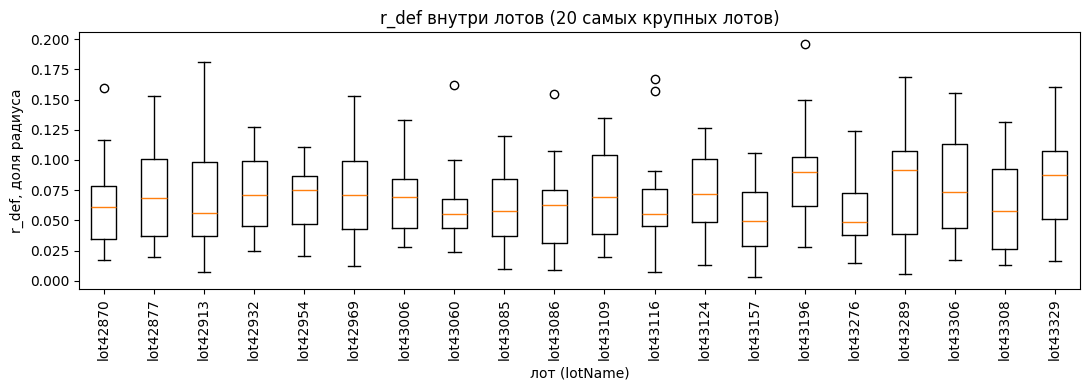

In [5]:
top = x_df["lotName"].value_counts().head(20).index
data = [x_df.loc[x_df["lotName"] == lot, "r_def"].values for lot in top]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot(data)
ax.set_xticks(range(1, len(top) + 1), top, rotation=90)
ax.set_xlabel("лот (lotName)")
ax.set_ylabel("r_def, доля радиуса")
ax.set_title("r_def внутри лотов (20 самых крупных лотов)")
plt.tight_layout()
plt.show()

**Почему величина случайная.** Внутри одного лота (одна партия, одни условия обработки) $r_{def}$ сильно меняется: в первых лотах таблицы от ~0.003 до ~0.16, а стандартное отклонение внутри лота (~0.03) почти такое же, как по всей выборке (0.037). Разложение дисперсии это подтверждает: внутрилотовая компонента 0.00133 из 0.00138 общей, ICC ≈ 0.07. То есть только ~7% разброса связано с различиями между партиями, остальное — разброс от пластины к пластине при одинаковых условиях. Формулы, по которой можно заранее посчитать $r_{def}$ для пластины, нет, значит, это случайная величина.

ICC у $r_{def}$ ниже, чем у n_edge (0.155): на общий уровень брака лот влияет заметнее, чем на то, в какую сторону сдвинут брак.

#### Режимы: зависимость r_def от числа дефектов

Так как пластин с одним дефектом нет, «режимы» здесь другие: масштаб $r_{def}$ должен зависеть от $k$ как $1/\sqrt{k}$. Чтобы было с чем сравнивать, строим **нулевую модель**: берём сетку чипов в круге (квадратная решётка, 517 чипов, почти как 516 в данных), нормируем радиус так же, как в `src/features.py`, и для каждой пластины случайно выбираем столько же чипов, сколько у неё дефектов (`n_defect`). Центроид этих случайных чипов даёт $r_{def}$ «при полностью случайной раскладке».

Так как выбираем без возвращения (один чип не может быть дефектным дважды), а $k/516\approx 0.19$ — не маленькая доля, в масштаб входит поправка на конечность:
$$\sigma_k=\sqrt{\frac{s^2}{k}\cdot\frac{N_{grid}-k}{N_{grid}-1}}.$$

In [6]:
# нулевая модель: дефекты раскладываются по чипам равномерно и независимо
# сетка: квадратная решётка в круге, нормировка радиуса как в src/features.py
gg = np.arange(-20, 21)
GX, GY = np.meshgrid(gg, gg)
inside = GX**2 + GY**2 <= 12.9**2
grid = np.c_[GX[inside], GY[inside]].astype(float)
grid /= np.hypot(grid[:, 0], grid[:, 1]).max()
N_GRID = len(grid)
r_grid = np.hypot(grid[:, 0], grid[:, 1])
s2 = (grid**2).sum(axis=1).mean() / 2      # дисперсия одной координаты чипа
print(f"чипов в модельной сетке: {N_GRID} (в данных 516)")
print(f"чипов r > 0.8: {(r_grid > 0.8).sum()}, r < 0.5: {(r_grid < 0.5).sum()}")
print(f"дисперсия координаты чипа s^2 = {s2:.4f} (непрерывный диск: 0.25)")

def sigma_k(k):
    """Масштаб Рэлея для центроида k случайных чипов (выбор без возвращения)."""
    k = np.asarray(k, dtype=float)
    return np.sqrt(s2 / k * (N_GRID - k) / (N_GRID - 1))

def simulate_null(k_arr, rng):
    """r_def при случайной раскладке k_i дефектов по сетке, для каждой пластины."""
    out = np.empty(len(k_arr))
    for k in np.unique(k_arr):
        idx = np.flatnonzero(k_arr == k)
        sel = np.argsort(rng.random((len(idx), N_GRID)), axis=1)[:, :k]
        cen = grid[sel].mean(axis=1)
        out[idx] = np.hypot(cen[:, 0], cen[:, 1])
    return out

k_def = x_df["n_defect"].to_numpy()
r_null = simulate_null(k_def, rng)
pd.DataFrame({"данные": pd.Series(x.to_numpy()).describe(),
              "нулевая модель": pd.Series(r_null).describe()}).round(4)

чипов в модельной сетке: 517 (в данных 516)
чипов r > 0.8: 184, r < 0.5: 129
дисперсия координаты чипа s^2 = 0.2508 (непрерывный диск: 0.25)


,данные,нулевая модель
count,15881.0000,15881.0000
mean,0.0705,0.0581
std,0.0371,0.0308
min,0.0013,0.0000
25%,0.0425,0.0351
50%,0.0661,0.0542
75%,0.0937,0.0770
max,0.2563,0.2366


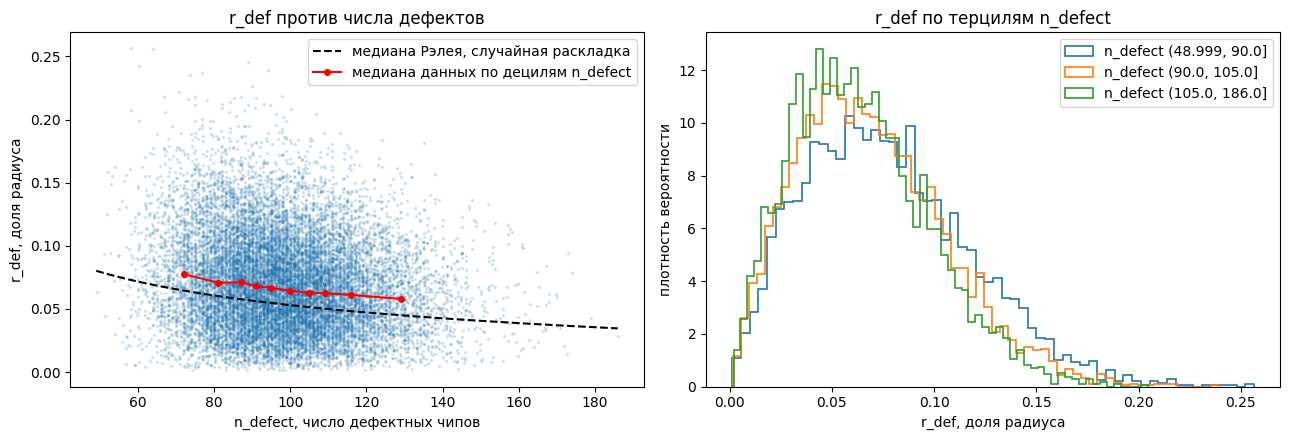

,k_mid,med_r,n,теория (случайно),отношение
n_defect,,,,,
"(48.999, 77.0]",72.0,0.0776,1698,0.0645,1.2016
"(77.0, 84.0]",81.0,0.0708,1745,0.0602,1.1762
"(84.0, 88.0]",87.0,0.0711,1383,0.0577,1.2323
"(88.0, 93.0]",91.0,0.0681,1732,0.0562,1.2126
"(93.0, 97.0]",95.0,0.0667,1507,0.0547,1.2191
"(97.0, 102.0]",100.0,0.0643,1786,0.0530,1.2135
"(102.0, 106.0]",105.0,0.0629,1278,0.0514,1.2224
"(106.0, 112.0]",109.0,0.0625,1601,0.0502,1.2451
"(112.0, 121.0]",116.0,0.0611,1618,0.0483,1.2658


In [7]:
# медиана r_def по группам n_defect против теории sigma_k * sqrt(2 ln 2)
bins_k = np.unique(np.quantile(k_def, np.linspace(0, 1, 11)))
grp_k = pd.cut(x_df["n_defect"], bins_k, include_lowest=True)
by_k = x_df.groupby(grp_k, observed=True).agg(k_mid=("n_defect", "median"),
                                               med_r=("r_def", "median"),
                                               n=("r_def", "size"))
by_k["теория (случайно)"] = sigma_k(by_k["k_mid"]) * np.sqrt(2 * np.log(2))
by_k["отношение"] = by_k["med_r"] / by_k["теория (случайно)"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(x_df["n_defect"] + rng.uniform(-0.3, 0.3, len(x_df)), x_df["r_def"], s=2, alpha=0.15)
kk = np.linspace(k_def.min(), k_def.max(), 200)
axes[0].plot(kk, sigma_k(kk) * np.sqrt(2 * np.log(2)), "k--", label="медиана Рэлея, случайная раскладка")
axes[0].plot(by_k["k_mid"], by_k["med_r"], "ro-", ms=4, label="медиана данных по децилям n_defect")
axes[0].set_xlabel("n_defect, число дефектных чипов")
axes[0].set_ylabel("r_def, доля радиуса")
axes[0].set_title("r_def против числа дефектов")
axes[0].legend()

for lab, sub in x_df.groupby(pd.qcut(x_df["n_defect"], 3), observed=True):
    axes[1].hist(sub["r_def"], bins=60, density=True, histtype="step", lw=1.2, label=f"n_defect {lab}")
axes[1].set_xlabel("r_def, доля радиуса")
axes[1].set_ylabel("плотность вероятности")
axes[1].set_title("r_def по терцилям n_defect")
axes[1].legend()
plt.tight_layout()
plt.show()
by_k.round(4)

Медиана $r_{def}$ действительно падает с ростом числа дефектов, примерно как $1/\sqrt{k}$: от 0.078 при $k\approx72$ до 0.058 при $k\approx129$. Но во всех децилях она в **1.18–1.29 раза** больше, чем при случайной раскладке. Получается, что закон $1/\sqrt{k}$ выполняется, но центроид смещается дальше, чем если бы дефекты падали на чипы независимо. По терцилям видно то же: чем больше дефектов, тем сильнее распределение прижато к нулю. Разные $k$ дают одну и ту же форму с разным масштабом, а не разные режимы.

### EDA & Distribution

#### Описательные статистики

In [8]:
xv = x.to_numpy()
N = len(xv)
desc = pd.Series({
    "n": N,
    "среднее": xv.mean(),
    "дисперсия (ddof=1)": xv.var(ddof=1),
    "ст. отклонение": xv.std(ddof=1),
    "медиана": np.median(xv),
    "q05": np.quantile(xv, 0.05),
    "q25": np.quantile(xv, 0.25),
    "q75": np.quantile(xv, 0.75),
    "q95": np.quantile(xv, 0.95),
    "min": xv.min(),
    "max": xv.max(),
    "асимметрия": stats.skew(xv),
    "эксцесс (избыточный)": stats.kurtosis(xv),
    "коэф. вариации": xv.std(ddof=1) / xv.mean(),
})
desc.round(5)

n                       15881.00000
среднее                     0.07045
дисперсия (ddof=1)          0.00138
ст. отклонение              0.03710
медиана                     0.06608
q05                         0.01802
q25                         0.04246
q75                         0.09373
q95                         0.13835
min                         0.00128
max                         0.25634
асимметрия                  0.66048
эксцесс (избыточный)        0.34166
коэф. вариации              0.52660
dtype: float64

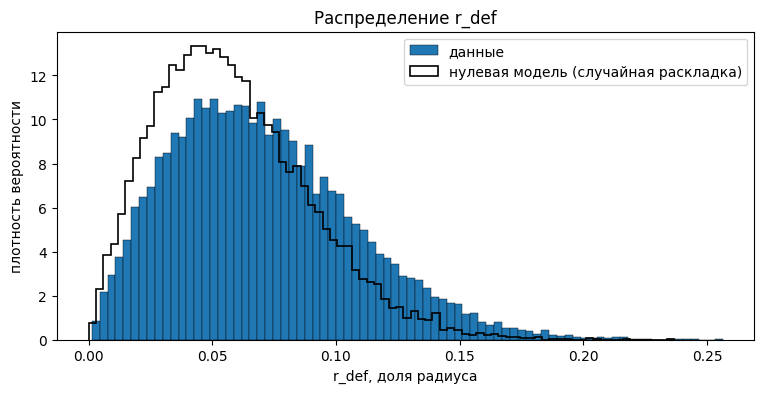

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(xv, bins=80, density=True, edgecolor="k", linewidth=0.3, label="данные")
ax.hist(r_null, bins=80, density=True, histtype="step", color="k", lw=1.2,
        label="нулевая модель (случайная раскладка)")
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности")
ax.set_title("Распределение r_def")
ax.legend()
plt.show()

Среднее 0.0705, медиана 0.066, максимум 0.256: центроид из ~100 точек никогда не уходит далеко от центра. Асимметрия 0.66 и эксцесс 0.34. Для сравнения, у распределения Рэлея при любом $\sigma$ асимметрия $\frac{2\sqrt\pi(\pi-3)}{(4-\pi)^{3/2}}\approx0.63$, эксцесс $\approx0.25$, коэффициент вариации $\sqrt{(4-\pi)/\pi}\approx0.523$ (у нас 0.527). Форма очень похожа на Рэлея. На гистограмме данные сдвинуты вправо относительно нулевой модели: это то же превышение масштаба, что и выше.

#### Подгонка распределений

In [10]:
# ММП, сдвиг фиксирован в 0; для беты ещё и масштаб = 1 (носитель [0, 1])
cand = {
    "Рэлей":   (stats.rayleigh,    dict(floc=0),           1),
    "Вейбулл": (stats.weibull_min, dict(floc=0),           2),
    "Гамма":   (stats.gamma,       dict(floc=0),           2),
    "Бета":    (stats.beta,        dict(floc=0, fscale=1), 2),
    "Райс":    (stats.rice,        dict(floc=0),           2),
}
fits, rows = {}, {}
for name, (dist, kw, k) in cand.items():
    params = dist.fit(xv, **kw)
    ll = dist.logpdf(xv, *params).sum()
    fits[name] = (dist, params, k)
    rows[name] = {"параметры": ", ".join(f"{p:.4g}" for p in params),
                  "число параметров": k, "logL": ll, "AIC": 2 * k - 2 * ll,
                  "1 - F(1)": dist.sf(1, *params)}
aic_table = pd.DataFrame(rows).T
aic_table["dAIC"] = aic_table["AIC"].astype(float) - aic_table["AIC"].astype(float).min()
aic_table.sort_values("dAIC")

,параметры,число параметров,logL,AIC,1 - F(1),dAIC
Рэлей,"0, 0.0563",1,30685.669729,-61369.339459,0.0,0.000000
Вейбулл,"1.986, 0, 0.0795",2,30686.344556,-61368.689112,0.0,0.650347
Райс,"0.001473, 0, 0.0563",2,30685.669729,-61367.339459,0.0,2.000000
Бета,"2.939, 38.83, 0, 1",2,30533.937203,-61063.874407,0.0,305.465052
Гамма,"3.116, 0, 0.02261",2,30458.436895,-60912.87379,0.0,456.465669


In [11]:
# смесь Рэлеев по числу дефектов: sigma_i = c * sigma_k(k_i) / sqrt(s2)
# при случайной раскладке c = sqrt(s2); c оцениваем по ММП (явная формула)
a_i = sigma_k(k_def) / np.sqrt(s2)
c_hat = np.sqrt(np.sum((xv / a_i) ** 2) / (2 * N))
c_0 = np.sqrt(s2)
ll_mix_hat = stats.rayleigh.logpdf(xv, scale=c_hat * a_i).sum()
ll_mix_0 = stats.rayleigh.logpdf(xv, scale=c_0 * a_i).sum()
pd.DataFrame({
    "c": [c_0, c_hat],
    "число параметров": [0, 1],
    "logL": [ll_mix_0, ll_mix_hat],
    "AIC": [-2 * ll_mix_0, 2 - 2 * ll_mix_hat],
}, index=["Рэлей(k), c из случайной раскладки", "Рэлей(k), c по ММП"]).assign(
    **{"(c_hat / c_0)^2": [np.nan, (c_hat / c_0) ** 2]})

,c,число параметров,logL,AIC,(c_hat / c_0)^2
"Рэлей(k), c из случайной раскладки",0.500837,0,29440.244508,-58880.489016,NaN
"Рэлей(k), c по ММП",0.611362,1,30889.311271,-61776.622542,1.490065


In [12]:
# LR-тесты вложенных моделей
ll = aic_table["logL"].astype(float)
lr_w = 2 * (ll["Вейбулл"] - ll["Рэлей"])        # Рэлей = Вейбулл с c = 2
lr_r = 2 * (ll["Райс"] - ll["Рэлей"])           # Рэлей = Райс с nu = 0 (граница: p / 2)
pd.DataFrame({"LR": [lr_w, lr_r],
              "p-value": [stats.chi2.sf(lr_w, 1), 0.5 * stats.chi2.sf(lr_r, 1)]},
             index=["Рэлей против Вейбулла", "Рэлей против Райса"])

,LR,p-value
Рэлей против Вейбулла,1.349653e+00,0.245339
Рэлей против Райса,-2.764864e-10,0.500000


**Что получилось.**
- Лучший AIC у **Рэлея** ($\hat\sigma=0.0563$), хотя у него всего один параметр. Ожидаемое среднее $\hat\sigma\sqrt{\pi/2}=0.0706$ совпадает с выборочным 0.0705.
- Вейбулл дал параметр формы $\hat c=1.986$, почти ровно 2, а Рэлей — это и есть Вейбулл с $c=2$. LR-тест: $p=0.25$, лишний параметр ничего не добавляет.
- У Райса параметр сдвига $\hat b=\nu/\sigma\approx0.0015$, то есть практически 0, и модель вырождается в Рэлея ($LR\approx0$). Значит, **систематического смещения центра** карты относительно центра пластины не видно: если бы центр был сдвинут, центроид всё время уходил бы в одну сторону, и Райс был бы заметно лучше.
- Гамма и бета хуже на $\Delta AIC\approx 305$ и $456$: у них «неправильная» форма левого хвоста (у Рэлея плотность растёт линейно от нуля, $f(r)\propto r$).
- $1-F(1)=0$ у всех моделей, поэтому то, что носитель Рэлея $[0,\infty)$, а не $[0,1]$, на практике не мешает.

Модель «смесь Рэлеев по $k$» использует число дефектов каждой пластины. Это условная модель $f(r\mid k)$, поэтому её AIC сравниваем только между её вариантами. С $c$, подобранным по ММП, она лучше, чем с теоретическим $c_0$ (−61777 против −58880). $(\hat c/c_0)^2=1.49$: дисперсия координат центроида в 1.5 раза больше, чем при случайной раскладке.

#### Графики согласия

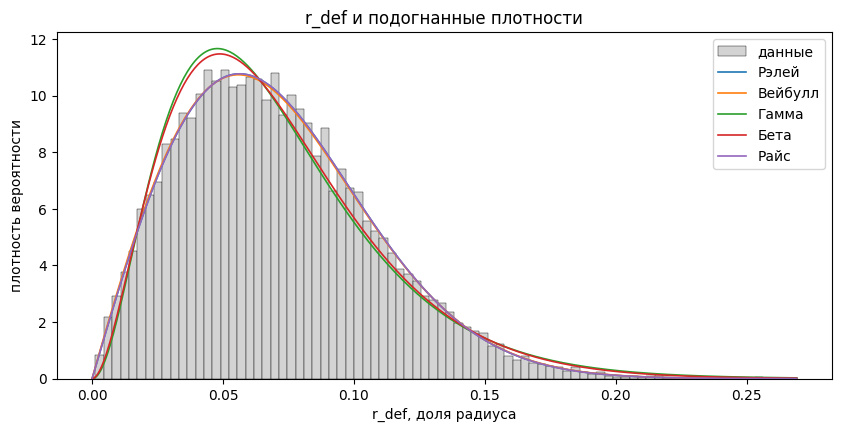

In [13]:
grid_r = np.linspace(0, xv.max() * 1.05, 400)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(xv, bins=80, density=True, color="lightgray", edgecolor="k", linewidth=0.3, label="данные")
for name, (dist, params, k) in fits.items():
    ax.plot(grid_r, dist.pdf(grid_r, *params), lw=1.2, label=name)
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности")
ax.set_title("r_def и подогнанные плотности")
ax.legend()
plt.show()

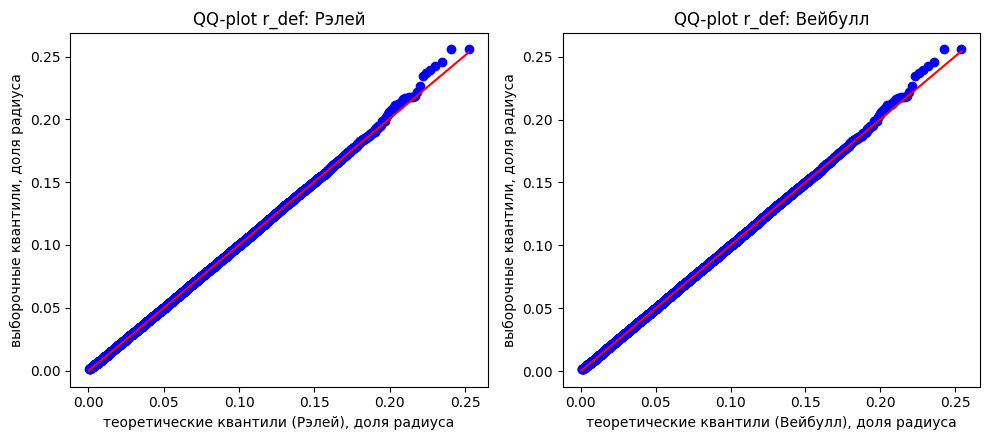

In [14]:
order = aic_table.sort_values("dAIC").index
show = list(dict.fromkeys([order[0], order[1], "Рэлей"]))
fig, axes = plt.subplots(1, len(show), figsize=(5 * len(show), 4.5))
for ax, name in zip(axes, show):
    dist, params, k = fits[name]
    stats.probplot(xv, dist=dist, sparams=params, plot=ax)
    ax.set_title(f"QQ-plot r_def: {name}")
    ax.set_xlabel(f"теоретические квантили ({name}), доля радиуса")
    ax.set_ylabel("выборочные квантили, доля радиуса")
plt.tight_layout()
plt.show()

На QQ-графиках Рэлея и Вейбулла точки лежат на прямой почти по всей длине. Небольшое отклонение есть только в самом правом хвосте ($r_{def}>0.2$, это десятки пластин из 15881): там данных чуть больше, чем предсказывает модель. Скорее всего, это пластины, где брак действительно собран с одной стороны (начало паттерна, который эксперты не отметили).

#### Нормализация

Зачем нормализация: многие классические методы (t-тест, доверительные интервалы через $z$, линейная регрессия) предполагают нормальность или хотя бы симметрию. Кроме того, разные величины удобно сравнивать в одной шкале. Пробуем:
- **z-score** $z=(x-\bar x)/s$ — только сдвиг и масштаб, форма (асимметрия, эксцесс) не меняется;
- **логит** $\log\frac{r}{1-r}$ — переводит $(0,1)$ в $\mathbb R$. Точных 0 и 1 в данных нет, обрезать ничего не пришлось;
- **Бокс–Кокс** $\frac{x^\lambda-1}{\lambda}$ с $\lambda$ по ММП ($r_{def}>0$, сдвиг не нужен);
- **физическая нормировка** $u=r_{def}/\sigma_k$ — делим на масштаб, ожидаемый при данном числе дефектов, чтобы убрать зависимость от $k$.

In [15]:
eps = 1e-6
n_clip = int(((xv < eps) | (xv > 1 - eps)).sum())
xc = np.clip(xv, eps, 1 - eps)
print("обрезано точек у 0 и 1:", n_clip)
x_bc, lam_bc = stats.boxcox(xv)
print(f"Бокс-Кокс: lambda = {lam_bc:.4f}")

transforms = {
    "исходные": xv,
    "z-score": (xv - xv.mean()) / xv.std(ddof=1),
    "логит": np.log(xc / (1 - xc)),
    "Бокс-Кокс": x_bc,
    "u = r / sigma_k": xv / sigma_k(k_def),
}
pd.DataFrame({name: {"асимметрия": stats.skew(t), "эксцесс (избыточный)": stats.kurtosis(t)}
              for name, t in transforms.items()}).T.round(4)

обрезано точек у 0 и 1: 0
Бокс-Кокс: lambda = 0.5187


,асимметрия,эксцесс (избыточный)
исходные,0.6605,0.3417
z-score,0.6605,0.3417
логит,-0.9578,1.5965
Бокс-Кокс,-0.0363,-0.2608
u = r / sigma_k,0.6007,0.1548


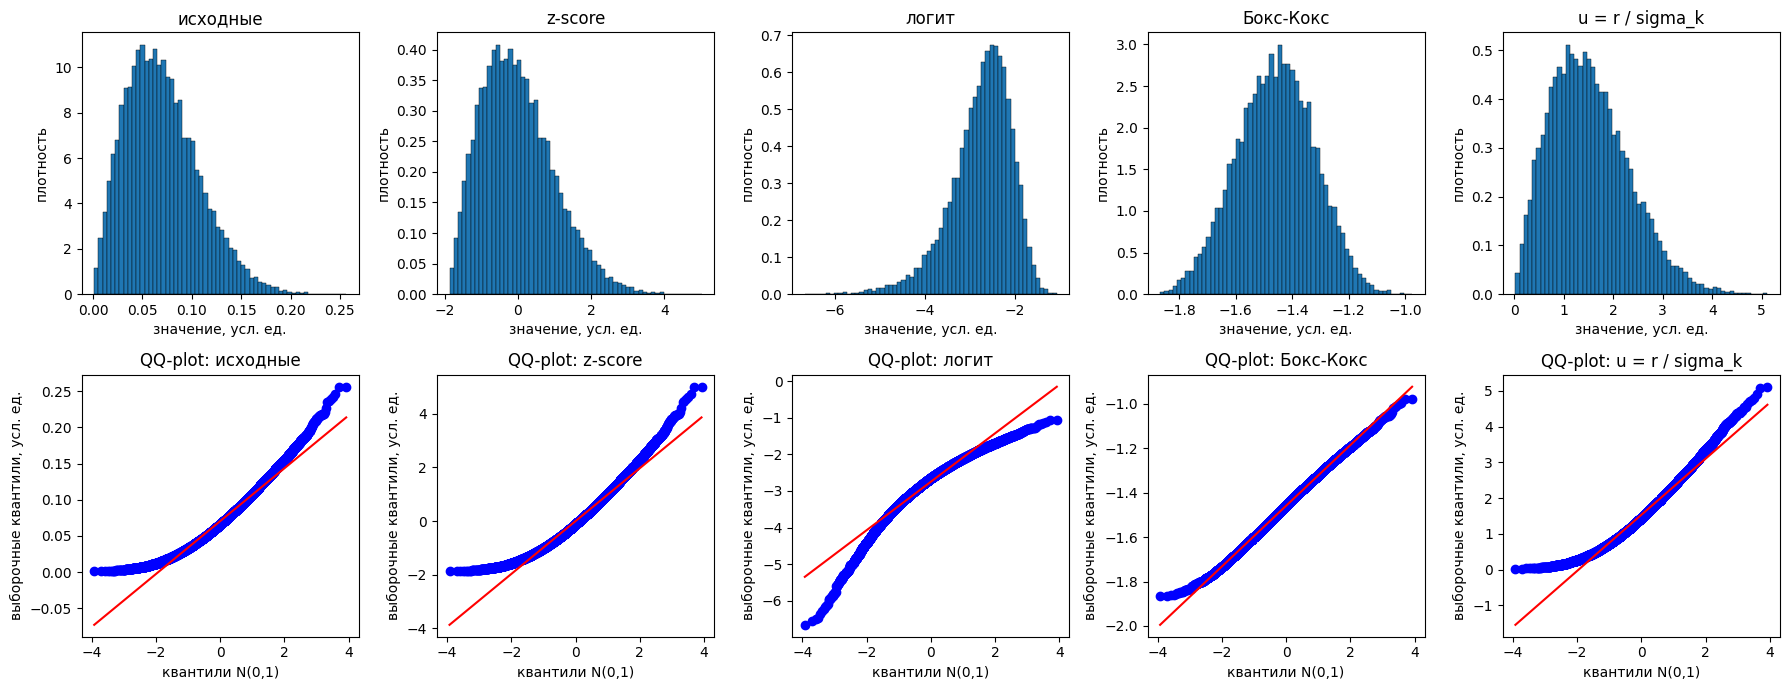

In [16]:
fig, axes = plt.subplots(2, len(transforms), figsize=(18, 7))
for j, (name, t) in enumerate(transforms.items()):
    axes[0, j].hist(t, bins=60, density=True, edgecolor="k", linewidth=0.3)
    axes[0, j].set_title(name)
    axes[0, j].set_xlabel("значение, усл. ед.")
    axes[0, j].set_ylabel("плотность")
    stats.probplot(t, dist="norm", plot=axes[1, j])
    axes[1, j].set_title(f"QQ-plot: {name}")
    axes[1, j].set_xlabel("квантили N(0,1)")
    axes[1, j].set_ylabel("выборочные квантили, усл. ед.")
plt.tight_layout()
plt.show()

- z-score форму не изменил: асимметрия 0.66 осталась.
- Логит стал хуже исходных данных: значения $r_{def}$ маленькие (≈0.07), при малых $r$ логит $\approx\log r$, и он сильно растягивает левый хвост (асимметрия −0.96, эксцесс 1.6).
- Бокс–Кокс дал $\lambda\approx0.52$, то есть почти $\sqrt{r}$, и распределение стало почти симметричным (асимметрия −0.04). По QQ-plot оно близко к нормальному, отклонения есть только в хвостах.
- $u=r/\sigma_k$ убирает зависимость от $k$, но форму оставляет рэлеевской (асимметрия 0.60), как и должно быть.

Вывод: нормальность здесь можно получить преобразованием $\approx\sqrt{r}$. Но для анализа это не нужно: у величины есть естественная модель (Рэлей), и тесты лучше проводить в ней или непараметрическими методами.

#### Математическая база

**Распределение Рэлея.** Пусть $X,Y\sim\mathcal N(0,\sigma^2)$ независимы. Тогда $R=\sqrt{X^2+Y^2}$ имеет распределение Рэлея. Функцию распределения получаем, переходя к полярным координатам:
$$P(R\le r)=\int_0^{2\pi}\!\!\int_0^r\frac{1}{2\pi\sigma^2}e^{-\rho^2/2\sigma^2}\rho\,d\rho\,d\varphi=1-e^{-r^2/2\sigma^2},\qquad f(r)=\frac{r}{\sigma^2}e^{-r^2/2\sigma^2},\ r\ge0.$$

Параметр один, масштаб $\sigma>0$. Моменты:
$$\mathbb E R=\sigma\sqrt{\pi/2},\qquad \operatorname{Var}R=\frac{4-\pi}{2}\sigma^2,\qquad \text{медиана}=\sigma\sqrt{2\ln2}.$$
Оценка ММП: $\hat\sigma^2=\frac{1}{2n}\sum r_i^2$ (несложно получить, приравняв производную логарифма правдоподобия к нулю).

Где возникает: модуль двумерного вектора с независимыми нормальными компонентами. Примеры: промах при стрельбе по мишени, амплитуда узкополосного шума (Райс, 1945), скорость ветра. У нас «вектор» — смещение центроида дефектов. По ЦПТ его координаты почти нормальны, если дефектов много и они независимы. Для $k$ случайных чипов $\sigma^2=s^2/k$ (с поправкой на выбор без возвращения), и при $s^2=1/4$ получаем $\sigma=1/(2\sqrt k)$.

**Близкие распределения**, которые мы тоже проверяли:
- **Вейбулл** $f(x)=\frac{c}{\lambda}\left(\frac{x}{\lambda}\right)^{c-1}e^{-(x/\lambda)^c}$, $\mathbb EX=\lambda\Gamma(1+1/c)$. При $c=2$ это Рэлей с $\lambda=\sigma\sqrt2$. Используется в надёжности и для времени до отказа.
- **Райс** — модуль вектора $\mathcal N(\nu,\sigma^2)\times\mathcal N(0,\sigma^2)$, то есть Рэлей со сдвигом центра $\nu$; при $\nu=0$ совпадает с Рэлеем.
- **Бета** $f(x)=\frac{x^{\alpha-1}(1-x)^{\beta-1}}{B(\alpha,\beta)}$ на $[0,1]$, $\mathbb EX=\frac{\alpha}{\alpha+\beta}$. Это универсальная модель для долей, физического смысла для центроида у неё нет. Для **одного** равномерно брошенного на диск дефекта $P(R\le r)=r^2$, то есть $R\sim\text{Beta}(2,1)$, но у нас таких пластин нет.

**Чем Рэлей хорош и чем плох для наших данных.** Хорош тем, что выводится из простой модели (ЦПТ для центроида), имеет один параметр и описывает форму почти идеально. Плох тем, что предполагает независимость дефектов. На деле масштаб в $\sqrt{1.49}\approx1.22$ раза больше теоретического, то есть дефекты не независимы. Кроме того, $\sigma$ зависит от $k$, так что строго говоря выборка — это смесь Рэлеев. Но $k$ меняется не сильно (коэффициент вариации ~18%), и смесь почти не отличается от одного Рэлея.

### Independence & Estimations

#### Состоятельность оценок

Оценка $\hat\theta_n$ **состоятельна**, если $\hat\theta_n\to\theta$ по вероятности при $n\to\infty$. Для среднего и дисперсии это следует из закона больших чисел. Для медианы нужно, чтобы плотность в точке медианы была положительной, и для непрерывной $r_{def}$ это выполняется (в отличие от n_edge, где медиана «залипает» на целых значениях).

Генеральной совокупностью считаем всю выборку (15881 пластина). Для каждого размера $n$ делаем 100 выборок с возвращением и строим полосу 5–95% оценок.

Результат: все три оценки сходятся к генеральным значениям, полоса сужается. В log-log наклон ширины полосы $\approx -0.49,\,-0.48,\,-0.48$ для среднего, дисперсии и медианы. Это близко к теоретическим $-1/2$ (разброс $\propto 1/\sqrt n$). Медиана здесь ведёт себя так же хорошо, как среднее, потому что величина непрерывная.

In [17]:
sizes = np.unique(np.logspace(1, np.log10(N), 15).astype(int))
true_vals = {"среднее": xv.mean(), "дисперсия": xv.var(ddof=1), "медиана": np.median(xv)}

rows = []
for n in sizes:
    est = np.array([[s.mean(), s.var(ddof=1), np.median(s)]
                    for s in (rng.choice(xv, n, replace=True) for _ in range(N_REP))])
    for j, name in enumerate(true_vals):
        q05, q50, q95 = np.quantile(est[:, j], [0.05, 0.5, 0.95])
        rows.append({"n": n, "оценка": name, "q05": q05, "медиана": q50, "q95": q95})
cons = pd.DataFrame(rows)
cons["ширина 5-95%"] = cons["q95"] - cons["q05"]
cons.pivot(index="n", columns="оценка", values="ширина 5-95%").round(5)

оценка,дисперсия,медиана,среднее
n,,,
10,0.00196,0.05136,0.03628
16,0.00163,0.03862,0.03094
28,0.00115,0.02503,0.02486
48,0.00087,0.01920,0.01469
82,0.00079,0.01793,0.01324
139,0.00056,0.01175,0.00979
235,0.00043,0.00978,0.00826
398,0.00034,0.00702,0.00566
674,0.00026,0.00550,0.00425


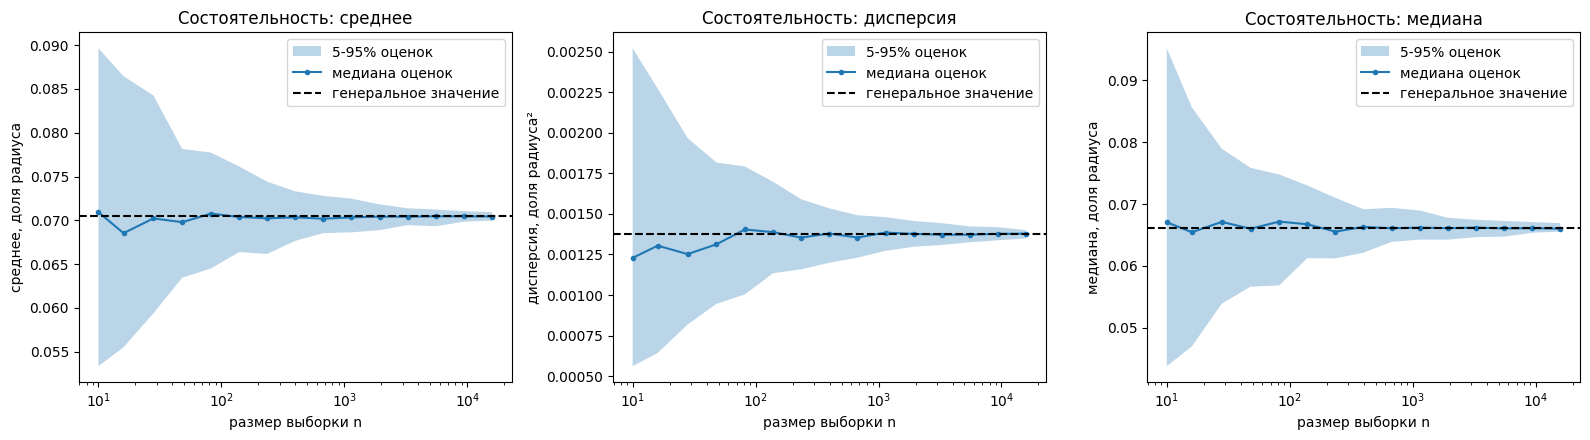

In [18]:
units = {"среднее": "доля радиуса", "дисперсия": "доля радиуса²", "медиана": "доля радиуса"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, true_vals):
    c = cons[cons["оценка"] == name]
    ax.fill_between(c["n"], c["q05"], c["q95"], alpha=0.3, label="5-95% оценок")
    ax.semilogx(c["n"], c["медиана"], "o-", ms=3, label="медиана оценок")
    ax.axhline(true_vals[name], color="k", ls="--", label="генеральное значение")
    ax.set_xlabel("размер выборки n")
    ax.set_ylabel(f"{name}, {units[name]}")
    ax.set_title(f"Состоятельность: {name}")
    ax.legend()
plt.tight_layout()
plt.show()

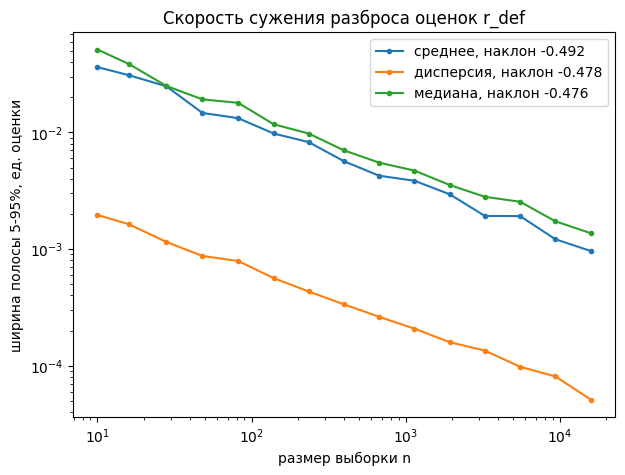

среднее     -0.4924
дисперсия   -0.4776
медиана     -0.4761
Name: наклон, dtype: float64

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
slopes = {}
for name in true_vals:
    c = cons[(cons["оценка"] == name) & (cons["ширина 5-95%"] > 0)]
    slopes[name] = np.polyfit(np.log10(c["n"]), np.log10(c["ширина 5-95%"]), 1)[0]
    ax.loglog(c["n"], c["ширина 5-95%"], "o-", ms=3, label=f"{name}, наклон {slopes[name]:.3f}")
ax.set_xlabel("размер выборки n")
ax.set_ylabel("ширина полосы 5-95%, ед. оценки")
ax.set_title("Скорость сужения разброса оценок r_def")
ax.legend()
plt.show()
pd.Series(slopes, name="наклон").round(4)

#### Выборки с возвращением и без

Берём 1000 пластин двумя способами. **С возвращением**: значения в выборке независимы и одинаково распределены, $\operatorname{Var}\bar X=\sigma^2/n$. **Без возвращения**: значения слегка зависимы (вытащенная пластина больше не попадётся), и появляется поправка на конечность совокупности:
$$\operatorname{Var}\bar X=\frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}.$$

Обе выборки хорошо совпадают с генеральной: средние 0.0708 и 0.0714 против 0.0705, квантили отличаются в третьем знаке. Формальные проверки (группы по децилям генеральной совокупности):
- χ² согласия выборки с возвращением с долями генеральной: $p=0.47$;
- χ² однородности выборки без возвращения и её **дополнения** (сравнивать с совокупностью, в которую выборка входит, некорректно): $p=0.33$;
- KS двух выборок: $p=0.56$ и $0.48$. Здесь KS корректен, так как величина непрерывная (для дискретной n_edge он консервативен).

Значит, случайной выборки из 1000 пластин достаточно, чтобы судить о распределении.

Монте-Карло (500 повторов на размер) показывает разницу подходов: при $n/N=0.063$ (n=1000) поправка всего $\sqrt{0.937}\approx0.97$, и подходы почти не различаются. При $n\to N$ разброс среднего без возвращения падает к нулю (при n = 15000 sd = 0.000074 против 0.000308 с возвращением): почти вся совокупность уже в выборке. Эмпирические точки ложатся на теоретические кривые.

In [20]:
s_with = x.sample(N_SAMPLE, replace=True, random_state=SEED)
s_without = x.sample(N_SAMPLE, replace=False, random_state=SEED)

def summary(s):
    return pd.Series({"n": len(s), "среднее": s.mean(), "дисперсия": s.var(ddof=1),
                      "q05": s.quantile(0.05), "q25": s.quantile(0.25), "медиана": s.median(),
                      "q75": s.quantile(0.75), "q95": s.quantile(0.95)})

pd.DataFrame({"генеральная": summary(x), "с возвращением": summary(s_with),
              "без возвращения": summary(s_without)}).round(5)

,генеральная,с возвращением,без возвращения
n,15881.00000,1000.00000,1000.00000
среднее,0.07045,0.07078,0.07141
дисперсия,0.00138,0.00133,0.00134
q05,0.01802,0.01735,0.01927
q25,0.04246,0.04347,0.04432
медиана,0.06608,0.06828,0.06634
q75,0.09373,0.09291,0.09542
q95,0.13835,0.13792,0.13919


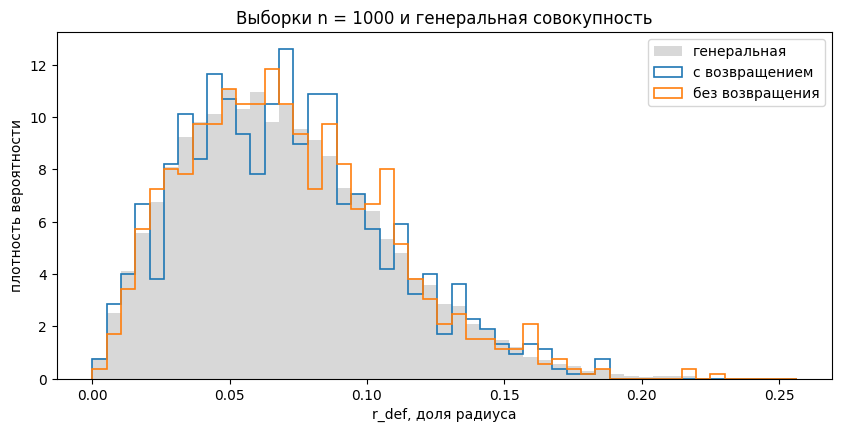

In [21]:
bins = np.linspace(0, xv.max(), 50)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(x, bins=bins, density=True, histtype="stepfilled", alpha=0.3, color="gray", label="генеральная")
ax.hist(s_with, bins=bins, density=True, histtype="step", lw=1.2, label="с возвращением")
ax.hist(s_without, bins=bins, density=True, histtype="step", lw=1.2, label="без возвращения")
ax.set_xlabel("r_def, доля радиуса")
ax.set_ylabel("плотность вероятности")
ax.set_title(f"Выборки n = {N_SAMPLE} и генеральная совокупность")
ax.legend()
plt.show()

In [22]:
# группы по децилям генеральной совокупности
edges = np.quantile(x, np.linspace(0, 1, 11))
edges[0], edges[-1] = -np.inf, np.inf
grp = lambda s: pd.cut(s, edges)

complement = x.drop(s_without.index)
tab = pd.crosstab(np.r_[np.zeros(len(s_without)), np.ones(len(complement))],
                  np.r_[grp(s_without).astype(str), grp(complement).astype(str)])
chi2_h, p_h, dof_h, E_h = stats.chi2_contingency(tab)
print(f"без возвращения vs дополнение: chi2 = {chi2_h:.3f}, df = {dof_h}, p = {p_h:.4f}, min E = {E_h.min():.1f}")

o_w = grp(s_with).value_counts().sort_index()
chi2_w, p_w = stats.chisquare(o_w.values, np.full(len(o_w), len(s_with) / len(o_w)))
print(f"с возвращением vs генеральная: chi2 = {chi2_w:.3f}, df = {len(o_w) - 1}, p = {p_w:.4f}")

for name, s, ref in [("с возвращением vs генеральная", s_with, x),
                     ("без возвращения vs дополнение", s_without, complement)]:
    r = stats.ks_2samp(s, ref)
    print(f"KS {name}: D = {r.statistic:.4f}, p = {r.pvalue:.4f}")

без возвращения vs дополнение: chi2 = 10.211, df = 9, p = 0.3337, min E = 100.0
с возвращением vs генеральная: chi2 = 8.640, df = 9, p = 0.4711
KS с возвращением vs генеральная: D = 0.0256, p = 0.5593
KS без возвращения vs дополнение: D = 0.0272, p = 0.4849


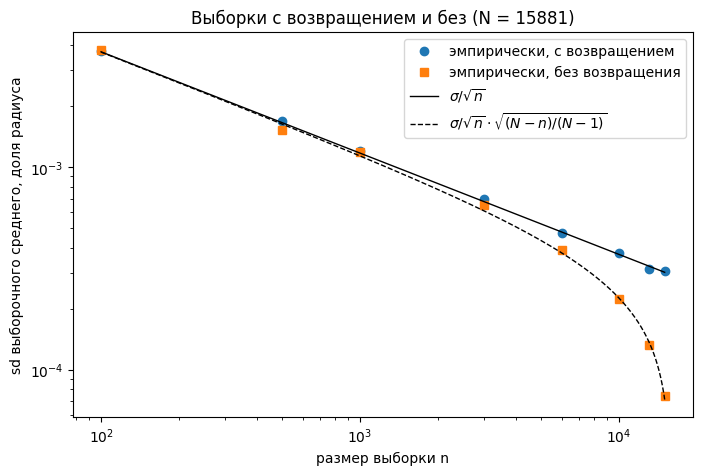

,n,n/N,sd с возвр.,sd без возвр.,теория sigma/sqrt(n),теория с FPC
0,100,0.006297,0.003746,0.003807,0.003710,0.003698
1,500,0.031484,0.001681,0.001520,0.001659,0.001633
2,1000,0.062968,0.001206,0.001190,0.001173,0.001136
3,3000,0.188905,0.000700,0.000654,0.000677,0.000610
4,6000,0.377810,0.000474,0.000390,0.000479,0.000378
5,10000,0.629683,0.000378,0.000224,0.000371,0.000226
6,13000,0.818588,0.000316,0.000133,0.000325,0.000139
7,15000,0.944525,0.000308,0.000074,0.000303,0.000071


In [23]:
sigma = xv.std(ddof=0)
n_grid = np.array([100, 500, 1000, 3000, 6000, 10000, 13000, 15000])
mc = []
for n in n_grid:
    m_with = [rng.choice(xv, n, replace=True).mean() for _ in range(N_MC)]
    m_without = [rng.choice(xv, n, replace=False).mean() for _ in range(N_MC)]
    mc.append({"n": n, "n/N": n / N, "sd с возвр.": np.std(m_with, ddof=1),
               "sd без возвр.": np.std(m_without, ddof=1),
               "теория sigma/sqrt(n)": sigma / np.sqrt(n),
               "теория с FPC": sigma / np.sqrt(n) * np.sqrt((N - n) / (N - 1))})
mc = pd.DataFrame(mc)

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(mc["n"], mc["sd с возвр."], "o", label="эмпирически, с возвращением")
ax.loglog(mc["n"], mc["sd без возвр."], "s", label="эмпирически, без возвращения")
nn = np.linspace(n_grid.min(), n_grid.max(), 400)
ax.loglog(nn, sigma / np.sqrt(nn), "k-", lw=1, label=r"$\sigma/\sqrt{n}$")
ax.loglog(nn, sigma / np.sqrt(nn) * np.sqrt((N - nn) / (N - 1)), "k--", lw=1,
          label=r"$\sigma/\sqrt{n}\cdot\sqrt{(N-n)/(N-1)}$")
ax.set_xlabel("размер выборки n")
ax.set_ylabel("sd выборочного среднего, доля радиуса")
ax.set_title(f"Выборки с возвращением и без (N = {N})")
ax.legend()
plt.show()
mc.round(6)

#### Проверка гипотез

**Гипотеза 1: $r_{def}$ имеет распределение Рэлея.**

- $H_0$: $r_{def}\sim\text{Rayleigh}(\sigma)$ при некотором $\sigma$. $H_1$: распределение другое.
- Уровень значимости $\alpha=0.05$.
- Статистики: KS ($D_n=\sup|F_n-F|$) и χ² по 30 равновероятным интервалам ($E_j=N/30\approx529$; ddof = число оценённых параметров).

Важная оговорка: если $\sigma$ оценена по тем же данным, обычный `kstest` даёт **завышенный** p-value. Модель подогнана под эти данные, поэтому $D_n$ получается меньше, чем «должно» (это проблема, которую Лиллиефорс решал для нормального распределения). Поэтому основной p-value считаем параметрическим бутстрапом `stats.goodness_of_fit`: генерируем выборки из подогнанного Рэлея, **на каждой заново оцениваем** $\sigma$ и считаем $D^*$.

Результат: наивный KS $p=0.68$, бутстрап $p=0.43$ — разница как раз показывает завышение. χ²: $\chi^2=15.9$ при $df=28$, $p=0.97$. **$H_0$ не отвергается**: при $n=15881$ это сильный результат, такая выборка заметила бы даже небольшое отклонение формы. У Вейбулла тоже хорошие p-value, но это тот же Рэлей с лишним параметром. Гамма и бета отвергаются ($p<10^{-35}$).

Оговорка: пластины одного лота не совсем независимы (ICC ≈ 0.07), поэтому p-value могут быть немного неточными.

In [24]:
best = order[0]
dist_b, par_b, k_b = fits[best]
print("лучшая модель по AIC:", best)

# 1) наивный KS с параметрами, оценёнными по тем же данным (p-value завышен)
ks_naive = stats.kstest(xv, dist_b.cdf, args=par_b)
print(f"наивный KS ({best}): D = {ks_naive.statistic:.4f}, p = {ks_naive.pvalue:.3e}")

# 2) параметрический бутстрап (обобщённый Лиллиефорс): параметры переоцениваются на каждой выборке
known = {"loc": 0, "scale": 1} if best == "Бета" else {"loc": 0}
gof = {}
for name in list(dict.fromkeys([best, "Рэлей"])):
    dist = fits[name][0]
    kn = {"loc": 0, "scale": 1} if name == "Бета" else {"loc": 0}
    gof[name] = stats.goodness_of_fit(dist, xv, known_params=kn, statistic="ks",
                                      n_mc_samples=B_GOF, rng=rng)
    print(f"goodness_of_fit KS ({name}): D = {gof[name].statistic:.4f}, p = {gof[name].pvalue:.4f}")

лучшая модель по AIC: Рэлей
наивный KS (Рэлей): D = 0.0057, p = 6.844e-01


goodness_of_fit KS (Рэлей): D = 0.0057, p = 0.4300


In [25]:
# 3) chi2 согласия на равновероятных интервалах: E_j = N / K
K = 30
def chi2_equiprob(name):
    dist, params, k = fits[name]
    cuts = dist.ppf(np.linspace(0, 1, K + 1), *params)
    O = np.histogram(xv, bins=cuts)[0]
    stat, p = stats.chisquare(O, np.full(K, N / K), ddof=k)
    return stat, K - 1 - k, p
chi2_tab = pd.DataFrame({name: dict(zip(["chi2", "df", "p-value"], chi2_equiprob(name)))
                         for name in fits}).T
chi2_tab["chi2 / df"] = chi2_tab["chi2"] / chi2_tab["df"]
chi2_tab.sort_values("chi2")

,chi2,df,p-value,chi2 / df
Рэлей,15.869844,28.0,9.677077e-01,0.566780
Райс,15.869844,27.0,9.553827e-01,0.587772
Вейбулл,19.266356,27.0,8.600924e-01,0.713569
Бета,240.746112,27.0,3.493717e-36,8.916523
Гамма,337.012090,27.0,2.828580e-55,12.481929


**Гипотеза 2: дефекты раскладываются по чипам случайно и независимо.**

Форма распределения — рэлеевская, но масштаб может не совпадать с тем, что даёт случайная раскладка. Проверяем это.

- $H_0$: для каждой пластины $k$ дефектных чипов выбраны случайно, тогда $(\hat c/c_0)^2=\frac{1}{2s^2}\cdot\overline{(r/\sigma_k)^2}\approx1$. $H_1$: разброс центроида больше, $(\hat c/c_0)^2>1$.
- Нулевое распределение статистики получаем Монте-Карло: 200 раз заново моделируем все 15881 пластину по нулевой модели.
- $\alpha=0.05$.

Результат: в данных $(\hat c/c_0)^2=1.49$, а в нулевой модели $1.00$ (5–95%: $[0.986, 1.015]$). Ни одна из 200 симуляций не дошла даже близко, $p=1/201\approx0.005$ (меньше получить при 200 повторах нельзя). KS нормированных $u$ против нулевой модели: $D=0.148$, $p\sim10^{-153}$. **$H_0$ отвергается.**

Интерпретация: центроид смещается в $\approx1.22$ раза дальше, чем при независимой раскладке. Значит, дефекты на пластине не независимы: есть небольшие скопления или слабая асимметрия (одна сторона пластины немного «грязнее» другой), причём направление каждый раз случайное. Если бы это был сдвиг центра карты, мы бы увидели Райса с $\nu>0$, а его нет. Похоже на перерассеяние n_edge ($D=1.45$): в обоих случаях разброс больше, чем даёт модель независимых дефектов.

(c_hat/c_0)^2: данные = 1.4901, нулевая модель: среднее = 0.9997, 5-95% = [0.9863, 1.0150]
Монте-Карло p-value = 0.0050 (N_NULL = 200)
KS u: данные против нулевой модели: D = 0.1482, p = 9.678e-153


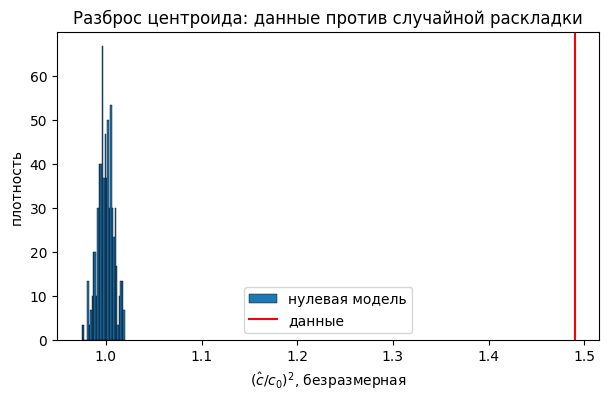

In [26]:
# статистика: (c_hat / c_0)^2 = средний квадрат нормированного радиуса / 2 / s2
def scale_ratio(r):
    return np.mean((r / sigma_k(k_def)) ** 2) / 2

ratio_obs = scale_ratio(xv)
ratio_null = np.array([scale_ratio(simulate_null(k_def, rng)) for _ in range(N_NULL)])
p_null = (1 + np.sum(ratio_null >= ratio_obs)) / (N_NULL + 1)
ks_null = stats.ks_2samp(xv / sigma_k(k_def), r_null / sigma_k(k_def))
print(f"(c_hat/c_0)^2: данные = {ratio_obs:.4f}, нулевая модель: среднее = {ratio_null.mean():.4f}, "
      f"5-95% = [{np.quantile(ratio_null, 0.05):.4f}, {np.quantile(ratio_null, 0.95):.4f}]")
print(f"Монте-Карло p-value = {p_null:.4f} (N_NULL = {N_NULL})")
print(f"KS u: данные против нулевой модели: D = {ks_null.statistic:.4f}, p = {ks_null.pvalue:.3e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(ratio_null, bins=30, density=True, edgecolor="k", linewidth=0.3, label="нулевая модель")
ax.axvline(ratio_obs, color="r", label="данные")
ax.set_xlabel(r"$(\hat c/c_0)^2$, безразмерная")
ax.set_ylabel("плотность")
ax.set_title("Разброс центроида: данные против случайной раскладки")
ax.legend()
plt.show()

**Гипотеза 3: распределение $r_{def}$ одинаково в Training и Test.**

- $H_0$: $P(X>Y)=P(Y>X)$, где $X$ — $r_{def}$ случайной пластины из Training, $Y$ — из Test. $H_1$: одна группа систематически больше (двусторонняя).
- Статистика Манна–Уитни $U$ (число пар с $x_i>y_j$, ничьи за 1/2), величина эффекта $U/(n_1n_2)$ (0.5 — нет эффекта).
- $\alpha=0.05$.

Результат для $r_{def}$: медианы 0.0651 (Training) и 0.0714 (Test), $p=6.6\cdot10^{-14}$, эффект 0.455. Формально $H_0$ отвергается. Но в Training больше дефектов на пластину (медиана n_defect 99 против 90, $p\sim10^{-160}$), а при большем $k$ центроид ближе к центру. Это **эффект состава**, а не другой характер расположения брака. Разбиение на Training/Test сделано по лотам: лоты не пересекаются (591 и 124 лота), поэтому разница в уровне брака между партиями переходит в разницу между Training и Test.

Для нормированной $u=r_{def}/\sigma_k$ эффект почти исчезает: $U/(n_1n_2)=0.486$, $p=0.017$. На уровне 0.05 разница ещё значима, но очень мала. Если учесть, что пластины внутри лота зависимы (из-за этого p-value занижены), практически расположение брака в двух частях одинаковое.

In [27]:
tr = x_df["trianTestLabel"] == "Training"
te = x_df["trianTestLabel"] == "Test"
u_all = xv / sigma_k(k_def)
res = {}
for name, val in [("r_def", xv), ("u = r_def / sigma_k", u_all), ("n_defect", k_def)]:
    a, b = val[tr.to_numpy()], val[te.to_numpy()]
    mw = stats.mannwhitneyu(a, b, alternative="two-sided", method="asymptotic")
    res[name] = {"n Training": len(a), "n Test": len(b),
                 "медиана Training": np.median(a), "медиана Test": np.median(b),
                 "U": mw.statistic, "p-value": mw.pvalue, "U/(n1*n2)": mw.statistic / (len(a) * len(b))}
mw_tab = pd.DataFrame(res).T
mw_tab

,n Training,n Test,медиана Training,медиана Test,U,p-value,U/(n1*n2)
r_def,13005.0,2876.0,0.065133,0.071379,17033501.5,6.602348e-14,0.455412
u = r_def / sigma_k,13005.0,2876.0,1.437077,1.483129,18167908.0,1.653568e-02,0.485742
n_defect,13005.0,2876.0,99.000000,90.000000,24702768.5,2.618588e-160,0.660460


#### Сводная таблица

In [28]:
summary_tab = pd.Series({
    "пластин (n)": N,
    "доля NaN": n_nan / len(df),
    "лотов": df["lotName"].nunique(),
    "среднее r_def": xv.mean(),
    "дисперсия r_def": xv.var(ddof=1),
    "медиана r_def": np.median(xv),
    "асимметрия": stats.skew(xv),
    "эксцесс": stats.kurtosis(xv),
    "ICC": icc,
    "лучшая модель (AIC)": best,
    "параметры лучшей модели": aic_table.loc[best, "параметры"],
    "dAIC Рэлея": aic_table.loc["Рэлей", "dAIC"],
    "c_0 (случайная раскладка)": c_0,
    "c_hat (ММП)": c_hat,
    "(c_hat/c_0)^2": ratio_obs,
    "Монте-Карло p (случайная раскладка)": p_null,
    f"наивный KS p ({best})": ks_naive.pvalue,
    f"бутстрап KS p ({best})": gof[best].pvalue,
    f"chi2 p ({best})": chi2_tab.loc[best, "p-value"],
    "Манн-Уитни p (r_def)": mw_tab.loc["r_def", "p-value"],
    "Манн-Уитни p (u)": mw_tab.loc["u = r_def / sigma_k", "p-value"],
}, dtype=object)
summary_tab.map(lambda v: f"{v:.6g}" if isinstance(v, (float, np.floating)) else v).to_frame("значение")

,значение
пластин (n),15881
доля NaN,0
лотов,715
среднее r_def,0.0704534
дисперсия r_def,0.00137648
медиана r_def,0.0660767
асимметрия,0.660484
эксцесс,0.341657
ICC,0.0710741
лучшая модель (AIC),Рэлей


#### Выводы

1. $r_{def}$ — случайная величина: внутри одного лота она меняется почти так же, как во всей выборке (ICC ≈ 0.07, то есть 93% дисперсии — разброс между пластинами одной партии).
2. В нашей выборке на каждой пластине есть хотя бы 49 дефектных чипов, поэтому $r_{def}$ определена везде (0% NaN), и режима «один дефект» нет. Масштаб $r_{def}$ убывает с числом дефектов примерно как $1/\sqrt{k}$, как и следует из ЦПТ для центроида.
3. Лучшая модель — **распределение Рэлея** с $\hat\sigma=0.056$. Её вывод из ЦПТ подтвердился на данных: у Вейбулла $\hat c\approx2$, у Райса сдвиг $\approx0$, форма (асимметрия, эксцесс, коэффициент вариации) совпадает с теоретической. Критерии согласия Рэлея не отвергают (бутстрап-KS $p=0.43$, χ² $p=0.97$). Гамма и бета подходят хуже.
4. При этом **гипотеза случайной независимой раскладки дефектов отвергнута**: центроид смещается в 1.22 раза дальше (дисперсия в 1.49 раза больше), чем если бы брак падал на чипы независимо. Для процесса это значит, что даже в классе none брак слегка кучкуется или распределён немного несимметрично, но в случайном направлении: систематического сдвига (например, всегда с одной стороны камеры) нет. Это согласуется с перерассеянием n_edge.
5. Почти все пластины имеют маленькое $r_{def}$ (95% меньше 0.14): в классе none нет сильной односторонней дефектности. Это логично, ведь такие пластины эксперты отнесли бы к паттернам (Edge-Loc, Loc, Scratch).
6. Различие Training/Test по $r_{def}$ объясняется в основном разным числом дефектов (лоты в частях разные). После нормировки на $\sigma_k$ разница практически исчезает.
7. Для оценок выполнена состоятельность (разброс $\propto n^{-1/2}$), выборки с возвращением и без согласуются с генеральной совокупностью, поправка на конечность совокупности видна только при $n/N$ порядка десятков процентов.

#### Литература

1. Гмурман В. Е. Теория вероятностей и математическая статистика. — М.: Юрайт, 2016.
2. Ивченко Г. И., Медведев Ю. И. Введение в математическую статистику. — М.: ЛКИ, 2010.
3. Кобзарь А. И. Прикладная математическая статистика. — М.: Физматлит, 2006.
4. Papoulis A., Pillai S. U. Probability, Random Variables and Stochastic Processes. 4th ed. — McGraw-Hill, 2002 (распределения Рэлея и Райса).
5. Rice S. O. Mathematical Analysis of Random Noise // Bell System Technical Journal. 1945. Vol. 24, № 1. P. 46–156.
6. Lilliefors H. W. On the Kolmogorov–Smirnov Test for Normality with Mean and Variance Unknown // JASA. 1967. Vol. 62, № 318. P. 399–402.
7. Efron B., Tibshirani R. J. An Introduction to the Bootstrap. — Chapman & Hall, 1993.
8. Wu M.-J., Jang J.-S. R., Chen J.-L. Wafer Map Failure Pattern Recognition and Similarity Ranking for Large-Scale Data Sets // IEEE Trans. Semicond. Manuf. 2015. Vol. 28, № 1. P. 1–12.
9. Koren I., Koren Z., Stapper C. H. A Statistical Study of Defect Maps of Large Area VLSI ICs // IEEE Trans. VLSI Systems. 1994. Vol. 2, № 2. P. 249–256.
10. Stapper C. H., Armstrong F. M., Saji K. Integrated Circuit Yield Statistics // Proc. IEEE. 1983. Vol. 71, № 4. P. 453–470.
11. Документация SciPy: `scipy.stats.rayleigh`, `weibull_min`, `rice`, `beta`, `goodness_of_fit`, `mannwhitneyu`.